# 31 · Narratives in the recommender's lists (work package 20)

**Work package 20** of the [applications plan](../../research/implementation_plan_applications.md), section 20.
What does the recommender recommend, seen from above? Tokens are grouped into **narratives**: clusters of tokens
traded by the same accounts (Louvain on the item-neighbour similarity over the whole history; descriptive, the same
clustering for every measure). At each of the 35 evaluation points a narrative's **strength** is its share of all
top-50 list slots of the frozen fixed blend, over every active account.

**Criterion (stated in the plan before any share was computed):** on the 14 test points, list shares are closer to
the narratives' share of the next 48 hours' new buyers than 14-day popularity shares are (mean absolute difference
over narratives, mean paired difference negative, 95% bootstrap interval over points excluding zero). The new
buyers of the last 48 hours ("recent flow") are reported alongside. Data from `src/scripts/build_narratives.py`.

In [1]:
import sys

sys.path.append("../scripts")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import narratives as nr
import plots
import protocol as pc
import stats

plots.style()
pd.set_option("display.float_format", "{:,.3f}".format)
WP20 = pc.RESULTS_DIR / "wp20"
clusters = pd.read_parquet(WP20 / "clusters.parquet")
table = pd.read_parquet(WP20 / "table.parquet")
print(f"{len(clusters):,} clustered tokens hold {clusters['list_slots'].sum() / table['list_count'].sum():.1%} of all list slots")

2,720 clustered tokens hold 96.8% of all list slots


## 1. Resolution

The smallest resolution at which the largest cluster holds under half of all list slots (the plan's rule).

In [2]:
clusterings = {r: clusters.set_index("token")[f"cluster_{r:g}"] for r in nr.RESOLUTIONS}
for r, c in clusterings.items():
    slots = table.groupby(table["token"].map(c))["list_count"].sum() / table["list_count"].sum()
    print(f"resolution {r:g}: {c.nunique()} clusters, largest {slots.max():.1%} of list slots")
RESOLUTION = nr.choose_resolution(table, clusterings)
cluster_of = nr.group_small(table, clusterings[RESOLUTION])
print(f"chosen: {RESOLUTION:g}; {cluster_of[cluster_of >= 0].nunique()} narratives hold at least 2% of list slots at some point")

resolution 0.5: 6 clusters, largest 83.4% of list slots
resolution 1: 7 clusters, largest 61.0% of list slots
resolution 2: 89 clusters, largest 26.5% of list slots
resolution 4: 347 clusters, largest 14.1% of list slots
chosen: 2; 8 narratives hold at least 2% of list slots at some point


## 2. What the narratives are

Each narrative's most-listed tokens (symbols as on chain). The names below were given after reading these lists;
they do not enter any number.

In [3]:
named = clusters.assign(narrative=clusters["token"].map(cluster_of))
top = (named[named["narrative"] >= 0].sort_values("list_slots", ascending=False).groupby("narrative")
       .agg(tokens=("token", "size"), slots=("list_slots", "sum"), top_symbols=("symbol", lambda s: ", ".join(map(str, s.head(12))))))  # fmt: skip
top["share_of_slots"] = top["slots"] / table["list_count"].sum()
pd.set_option("display.max_colwidth", 140)
top.sort_values("slots", ascending=False)

,tokens,slots,top_symbols,share_of_slots
narrative,,,,
6,112,65815655,"UNI, LINK, AAVE, PEPE, SHIB, SPX, ENA, LDO, CRV, SKY, SYN, PENDLE",0.265
4,153,52539757,"WBTC, DAI, PAXG, wstETH, XAUt, fwWETH, HEX, cbBTC, FRAX, tBTC, EURC, USDS",0.212
2,236,19700008,"BITCOIN, ADI, ASSET, POND, ELON, TRIA, REACT, pepecoin, DMTR, GME, GMT, PHA",0.079
10,46,18524730,"ASTEROID, wojak, MANYU, SERV, KEKIUS, DOGEUS, CATE, ASTEROID, ETHCAT, sato, PUPPY, IMD",0.075
0,767,18295753,"STARMIND, ETHLABS, VITALIK, VITALIK, YILONGMA, WOKE, STARMAN, MEEKO, WEBCAT, AIB, FERRET, Prometheus",0.074
1,457,10534449,"AMERICA250, KISHU, FIFA, PEIPEI, VITALIK, JOE, puppies, FROGE, LEASH, BabyDoge, MARV, ICP",0.042
3,224,6214830,"GREEN, ZIK, WIN, HLX, SWITCH, TAIKO, XDOGE, BMC, UXLINK, ATOS, PPT, DEXE",0.025
5,147,5415977,"XDOGE, AIB, ETHLABS, VITALIK, ELON, TOMLEE, DREAM, SPCX, STARMIND, MURAD, AIB, YILONGMA",0.022


In [4]:
NAMES = {  # given after reading the table above (most-listed tokens of each cluster)
    6: "Blue chips (UNI, LINK, AAVE, PEPE, SHIB)",
    4: "Bitcoin, gold, stablecoins (WBTC, DAI, PAXG)",
    2: "Mid-cap alts and AI (GME, GROK, OLAS)",
    10: "Cat, dog and frog memes (wojak, KEKIUS)",
    0: "Vitalik and AI memes (VITALIK, STARMIND)",
    1: "Old-school memes (KISHU, LEASH, BabyDoge)",
    3: "Small-cap DeFi (TAIKO, DEXE, BAL)",
    5: "Elon and SpaceX memes (ELON, SPCX, MURAD)",
}
narrative_of = cluster_of.map(lambda c: NAMES.get(c, f"cluster {c}") if c >= 0 else "other")
shares = nr.shares(table, narrative_of)
shares["part"] = shares["point"].map(pc.part_of)
shares.groupby("narrative")[nr.SHARES].mean().sort_values("list_share", ascending=False)

,list_share,outcome_share,popularity_share,recent_share
narrative,,,,
"Blue chips (UNI, LINK, AAVE, PEPE, SHIB)",0.266,0.156,0.144,0.126
"Bitcoin, gold, stablecoins (WBTC, DAI, PAXG)",0.212,0.157,0.157,0.153
other,0.209,0.308,0.337,0.382
"Mid-cap alts and AI (GME, GROK, OLAS)",0.080,0.075,0.080,0.081
"Cat, dog and frog memes (wojak, KEKIUS)",0.075,0.050,0.053,0.043
"Vitalik and AI memes (VITALIK, STARMIND)",0.072,0.088,0.082,0.082
"Old-school memes (KISHU, LEASH, BabyDoge)",0.041,0.094,0.083,0.082
"Small-cap DeFi (TAIKO, DEXE, BAL)",0.025,0.063,0.039,0.037
"Elon and SpaceX memes (ELON, SPCX, MURAD)",0.019,0.009,0.027,0.015


## 3. Strength over time

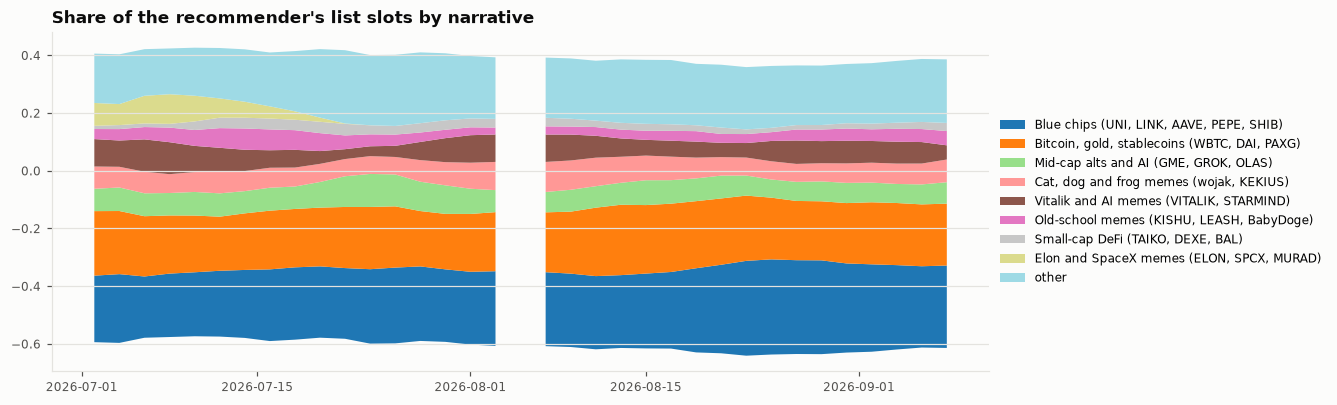

In [5]:
order = shares.groupby("narrative")["list_share"].mean().sort_values(ascending=False).index.tolist()
order = [n for n in order if n != "other"] + ["other"]
wide = shares.pivot(index="point", columns="narrative", values="list_share")[order]
fig, ax = plt.subplots(figsize=(11, 4))
colours = plt.cm.tab20(np.linspace(0, 1, len(order)))
ax.stackplot(wide.index, wide.T.to_numpy(), labels=order, colors=colours, baseline="wiggle")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), fontsize=8)
ax.set_title("Share of the recommender's list slots by narrative")
plt.show()

## 4. Do the lists anticipate where new buyers go? (the criterion)

In [6]:
def gaps(part: str) -> dict:
    frame = shares[shares["part"] == part]
    return {name: nr.mean_abs_gap(frame, share) for name, share in
            [("popularity (14 days)", "popularity_share"), ("recommender lists", "list_share"), ("recent flow (48 h)", "recent_share")]}  # fmt: skip


report = pd.concat({part: stats.compare(gaps(part), baseline="popularity (14 days)", metric="gap") for part in ("dev_a", "dev_b", "test")}, names=["part"]).droplevel(1)
report[["model", "points", "mean", "mean_difference", "interval_low", "interval_high", "wins"]]

,model,points,mean,mean_difference,interval_low,interval_high,wins
part,,,,,,,
dev_a,popularity (14 days),10,0.030,NaN,NaN,NaN,NaN
dev_a,recommender lists,10,0.055,0.025,0.020,0.029,10 of 10
dev_a,recent flow (48 h),10,0.030,-0.000,-0.006,0.006,6 of 10
dev_b,popularity (14 days),11,0.024,NaN,NaN,NaN,NaN
dev_b,recommender lists,11,0.053,0.029,0.023,0.033,11 of 11
dev_b,recent flow (48 h),11,0.028,0.004,-0.003,0.010,6 of 11
test,popularity (14 days),14,0.020,NaN,NaN,NaN,NaN
test,recommender lists,14,0.048,0.028,0.023,0.033,14 of 14
test,recent flow (48 h),14,0.027,0.007,0.004,0.011,11 of 14


In [7]:
row = report.loc["test"].set_index("model").loc["recommender lists"]
met = row["mean_difference"] < 0 and row["interval_high"] < 0
print(f"Test: mean gap {row['mean']:.4f} for the lists against {row['mean'] - row['mean_difference']:.4f} for popularity, "
      f"difference {row['mean_difference']:+.4f} [{row['interval_low']:+.4f}, {row['interval_high']:+.4f}] -> criterion {'MET' if met else 'NOT met'}")  # fmt: skip

Test: mean gap 0.0482 for the lists against 0.0199 for popularity, difference +0.0283 [+0.0231, +0.0334] -> criterion NOT met


## 5. Per narrative: list share against where new buyers went

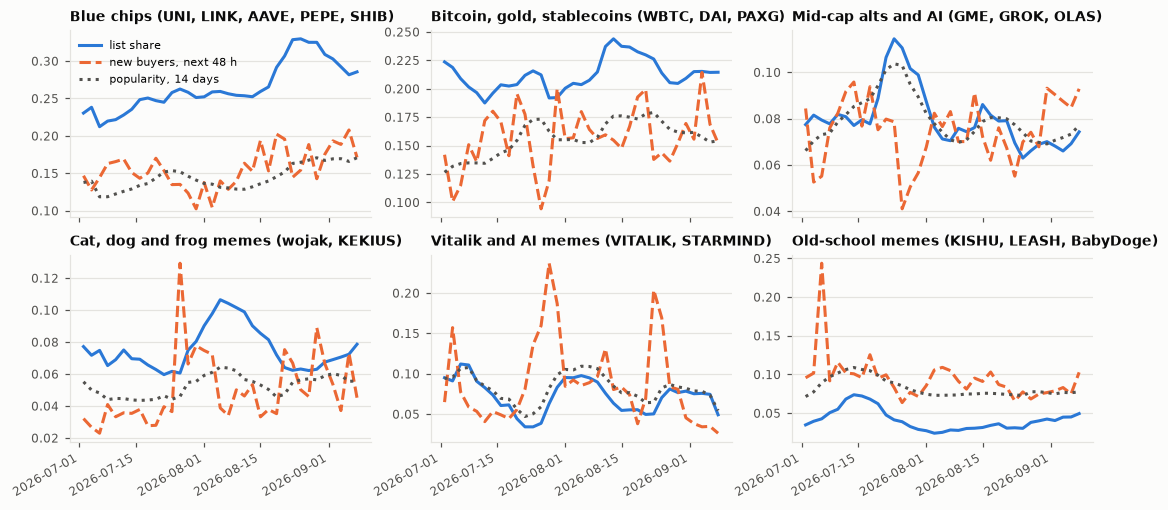

In [8]:
main = order[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
for ax, name in zip(axes.ravel(), main):
    part = shares[shares["narrative"] == name]
    ax.plot(part["point"], part["list_share"], color=plots.SERIES[0], label="list share")
    ax.plot(part["point"], part["outcome_share"], color=plots.SERIES[1], linestyle="--", label="new buyers, next 48 h")
    ax.plot(part["point"], part["popularity_share"], color=plots.INK_SECONDARY, linestyle=":", label="popularity, 14 days")
    ax.set_title(name, fontsize=9)
axes[0, 0].legend(fontsize=7)
fig.autofmt_xdate()
plt.show()

In [9]:
corr = shares.groupby("narrative").apply(lambda p: pd.Series({s: p[s].corr(p["outcome_share"], method="spearman") for s in ["list_share", "popularity_share", "recent_share"]}), include_groups=False)
corr.loc[order]

,list_share,popularity_share,recent_share
narrative,,,
"Blue chips (UNI, LINK, AAVE, PEPE, SHIB)",0.295,0.273,0.503
"Bitcoin, gold, stablecoins (WBTC, DAI, PAXG)",-0.066,0.029,0.206
"Mid-cap alts and AI (GME, GROK, OLAS)",-0.345,-0.118,0.489
"Cat, dog and frog memes (wojak, KEKIUS)",-0.076,0.411,0.525
"Vitalik and AI memes (VITALIK, STARMIND)",0.061,0.271,0.700
"Old-school memes (KISHU, LEASH, BabyDoge)",0.194,0.150,0.480
"Small-cap DeFi (TAIKO, DEXE, BAL)",0.366,0.268,0.367
"Elon and SpaceX memes (ELON, SPCX, MURAD)",0.591,0.600,0.664
other,0.046,0.249,0.332


## 6. What this shows

- **Eight narratives carry four fifths of the lists.** At resolution 2 (the plan's rule; at 0.5 and 1 one cluster
  holds 61-83% of all slots), the co-trading clusters read as recognisable themes: blue chips (UNI, LINK, AAVE, PEPE,
  SHIB), Bitcoin, gold and stablecoins (WBTC, DAI, PAXG, XAUt), mid-cap alts and AI tokens, and four separate meme
  families (cat, dog and frog memes; Vitalik and AI memes; old-school memes; Elon and SpaceX memes). The names are
  ours, read from each cluster's most-listed tokens.
- **The lists lean towards established tokens.** Blue chips and Bitcoin/stablecoins take 48% of the list slots on
  average but only 31% of the next two days' new buyers; the long tail ("other") takes 21% of the slots and 31% of
  the buyers. A top-50 list for every account repeats the safe, widely co-traded tokens.
- **The criterion is not met.** As a forecast of where new buyers go, the lists' narrative mix is further off than
  plain 14-day popularity (mean gap 0.048 against 0.020 on the test, 14 of 14 points), and recent flow is closer
  still over time (median Spearman with the outcome 0.49, against 0.19 for list shares). The lists are a portrait of
  what the model recommends, not a narrative forecast.
- **What it is good for:** a readable map of the recommender's output over time, and a check on its bias towards
  blue chips. The per-account result (recall) is unaffected: the lists win because they pick the right token for each
  account, not because their overall mix matches the market's.